In [1]:
import lsst.afw.math as afwMath
from lsst.afw.math import binImage
import lsst.afw.image as afwImage
from lsst.daf.butler import Butler
from lsst.pipe.tasks.visualizeVisit import VisualizeMosaicExpConfig, VisualizeMosaicExpTask
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm, trange
from photutils.background import Background2D, MedianBackground
from astropy.stats import SigmaClip
from matplotlib.patches import Polygon
from matplotlib.path import Path
from lsst.summit.utils.utils import getCameraFromInstrumentName
from lsst.afw.cameraGeom import FOCAL_PLANE
from matplotlib.path import Path
from photutils.segmentation import detect_sources, detect_threshold
from photutils.utils import circular_footprint
from astropy.convolution import convolve
from photutils.segmentation import make_2dgaussian_kernel
import lsst.summit.utils.plotting as splot

%matplotlib inline 
%matplotlib widget


In [2]:
def colorbar(mappable):
    from mpl_toolkits.axes_grid1 import make_axes_locatable
    import matplotlib.pyplot as plt
    last_axes = plt.gca()
    ax = mappable.axes
    fig = ax.figure
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.05)
    cbar = fig.colorbar(mappable, cax=cax)
    plt.sca(last_axes)
    return cbar

def doStarless(img):
    kernel = make_2dgaussian_kernel(1, size=1)   
    threshold = detect_threshold(img, 5.)
    segment_map = detect_sources(img, threshold, npixels=3)
    footprint = circular_footprint(radius=1)
    dilateMask = segment_map.make_source_mask(footprint=footprint)
    dilateAndSmoothMask = convolve(dilateMask, kernel)

    starlessImg = np.where(dilateAndSmoothMask != 0, np.median(img), img)
    return starlessImg

In [3]:
def fitPlane(image, order=1):
    '''
    Function to fit a 1st order Chebyshev polynomial to a binned image

    Parameters
    ----------
    image : `lsst.afw.image._image.ImageF`
        FFP image
    order : `int`
        Order of polynomial to fit

    Returns
    -------
    bkgdImage : `lsst.afw.image._image.ImageF`
        Chebyshev model of image
    '''
    # Hard code fit parameters for the notebook
    undersampleStyle = "INCREASE_NXNYSAMPLE"
    statsCtrl = afwMath.StatisticsControl()
    statsCtrl.setNanSafe(True)

    statsFlag = afwMath.stringToStatisticsProperty("MEAN")
    statsCtrl.setNumSigmaClip(1)
    statsCtrl.setNumIter(1)

    width = image.getWidth()
    height = image.getHeight()

    bctrl = afwMath.BackgroundControl(width, height, statsCtrl, statsFlag)
    bctrl.setUndersampleStyle(undersampleStyle)

    bkgd = afwMath.makeBackground(image, bctrl)
    bkgd.getStatsImage().variance = afwImage.ImageF(np.sqrt(bkgd.getStatsImage().image.array))

    actrl = afwMath.ApproximateControl(afwMath.ApproximateControl.CHEBYSHEV, order, order, True)
    undersampleStyle = afwMath.stringToUndersampleStyle(undersampleStyle)

    approx = bkgd.getApproximate(actrl, undersampleStyle)
    bkgdImage = approx.getImage()

    return bkgdImage


In [ ]:
import pandas as pd

# Read the CSV file
visitsl=[]
df_stray = pd.read_csv("stray_light_20250703.csv")
filt = ['u', 'g', 'r', 'i', 'z', 'y']
for f in filt:
    # Filter for band 'u' and rows where the last column contains 'tape'
    # mask_band = df_stray['band'] == f
    # mask_tape = df_stray['artifact'] ='tape'
    filtered = df_stray[(df_stray['band'] == f ) & (df_stray['artifact'] == 'tape') & (df_stray['target_name']== 'Rubin_SV_225_-40')]
    # Get the latest 10 lines (assuming the CSV is sorted by time, or use sort if there's a timestamp column)
    latest_10 = filtered.sample(n=10, random_state=42)
    
    print(f"Latest 10 entries for band {f}:")
    print(latest_10['exposure_id'])

    visitsl.append(latest_10['exposure_id'].tolist())

visits = [item for sublist in visitsl for item in sublist]
print(visits)


FileNotFoundError: [Errno 2] No such file or directory: 'stray_light_20250703.csv'

(2025052700826, 2025051900396, 2025052700810, 2025051900398, 2025060300074)

In [10]:
# First two are nightlyValidation17, so need to be re-constructed
# Last two are nightlyValidation18, which are still around
# visits = [2025051500395, 2025050500427, 2025051900386, 2025051900400]
# visits=[2025070300600, 2025060100658,2025060300083]
# visits=[latest_10['exposure_id'].iloc[0]]
# print(filtered[filtered['target_name'].str.contains('Rubin_SV_225_-40')]['target_name'])
count=0

In [ ]:
repo = "main"
butler = Butler(config=repo)

In [4]:
# coll=["LSSTCam/runs/DRP/20250501_20250609/w_2025_26/DM-51580", "LSSTCam/runs/DRP/20250420_20250521/w_2025_21/DM-51076","LSSTCam/runs/DRP/20250415_20250422/d_2025_04_23/DM-50409","u/ataranto/lsst_outputs","u/ataranto/baffle_outputs"]
coll=["u/ataranto/lsst_outputs"]

In [6]:
binning = 8
badMaskNames  = ["NO_DATA", "DETECTED", "DETECTED_NEGATIVE", "SAT", "BAD", "INTRP", "CR",]


detects = range(189)
bad = [120, 121, 122]
pIsrImsBinned = []
ids = []
for i in tqdm(detects):
    dataId = {"instrument": "LSSTCam", "exposure": 2025051900386  , "detector": i}
    if i in bad:
        continue
    else:
        try:
            im = butler.get("post_isr_image", dataId=dataId, collections=coll)
            bad_mask_bit_mask = im.mask.getPlaneBitMask(badMaskNames)
            msk = (im.mask.array.astype(int) & bad_mask_bit_mask) != 0
            im.getMaskedImage().image.array[msk] = np.nan  # Try removing detections &c.
            ids.append(i)
            pIsrImsBinned.append(binImage(im.getMaskedImage(), binning))    #by default this makes a mean bining, 
                                                                            #it does not associate the sum of the pixels to the new superpixel
        except:
            continue

100%|██████████| 189/189 [00:00<00:00, 1016312.12it/s]


In [14]:
# camera = butler.get("camera", instrument="LSSTCam", collections="LSSTCam/calib/DM-50716/unbounded")
camera = getCameraFromInstrumentName('LSSTCam')


In [15]:
mosConfig = VisualizeMosaicExpConfig()
mosConfig.binning = binning
mosTask = VisualizeMosaicExpTask(config=mosConfig)
pIsrMosaic = mosTask.run(pIsrImsBinned, camera, inputIds=ids).outputData

In [16]:
# Mask out the vignetted region before fitting
med = np.nanmedian(pIsrMosaic.array)

xCen, yCen = (pIsrMosaic.array.shape[0]/2, pIsrMosaic.array.shape[1]/2)
rad = (pIsrMosaic.array.shape[0] + pIsrMosaic.array.shape[1])/ 4  # Roughly the vignetted region radius
x = np.arange(1, pIsrMosaic.array.shape[1]+1)
y = x.reshape(-1, 1)
r = np.sqrt((x - xCen)**2 + (y - yCen)**2)
vignet = r >= rad

vignet = vignet[1:, :]

In [17]:
clone = pIsrMosaic.clone()
# Ensure vignet matches the shape of clone.array
vignet_mask = vignet
if vignet.shape != clone.array.shape:
	# Adjust vignet to match the shape of clone.array
	min_rows = min(vignet.shape[0], clone.array.shape[0])
	min_cols = min(vignet.shape[1], clone.array.shape[1])
	vignet_mask = vignet[:min_rows, :min_cols]
	clone.array = clone.array[:min_rows, :min_cols]
clone.array[vignet_mask] = np.nan

In [21]:
# First fit, ignoring the vignetted region
bkgd1 = fitPlane(clone, 3)

# sigma_clip = SigmaClip(sigma=3.0)
# bkg_estimator = MedianBackground()
# bkgd = Background2D(clone.array, (200, 200), filter_size=(3, 3), sigma_clip=sigma_clip, bkg_estimator=bkg_estimator)

In [22]:
# Now mask out bright residual peaks and fit again
want = (pIsrMosaic.array - bkgd1.array) >= 5
clone.array[want] = np.nan
bkgd = fitPlane(clone, 1)

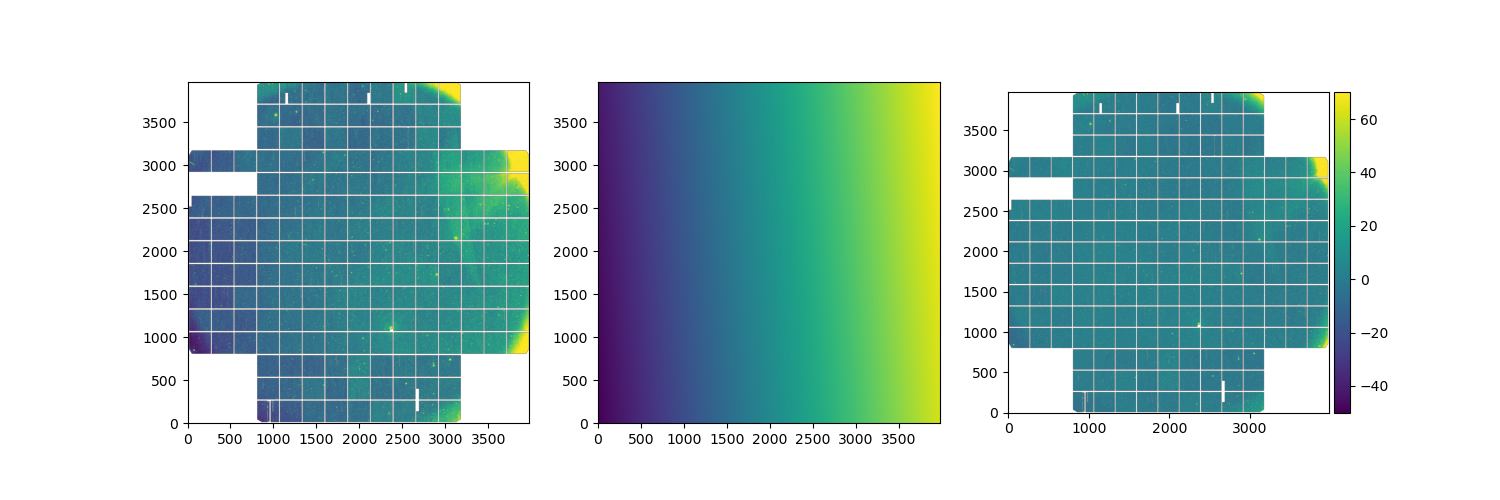

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(pIsrMosaic.array, origin="lower", vmin=med-20, vmax=med+30)
ax[1].imshow(bkgd.array, origin="lower")
cb = ax[2].imshow(pIsrMosaic.array - bkgd.array, vmin=-50, vmax=70, origin="lower")
colorbar(cb)
 
image=pIsrMosaic.array - bkgd.array

In [ ]:
print(visits[count])

2025052100121


: 

Click 4 times on the image to define the corners of your polygon.


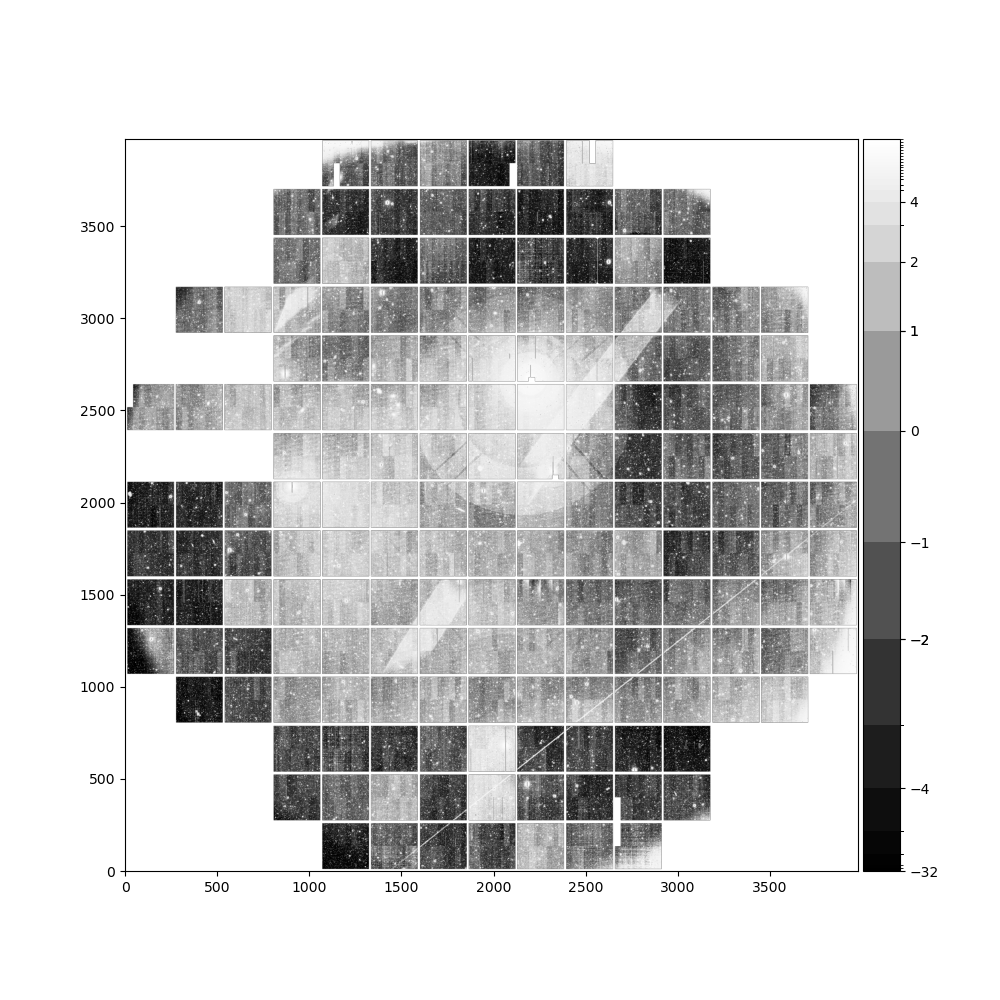

: 

: 

: 

: 

In [ ]:
med = np.nanmedian(image)

# plt.close('all')
fig = plt.figure(figsize=(10, 10))
cb = splot.plot(image, stretch='ccs', figure=fig)
ax = fig.axes[0]  # Use the axes created by splot.plot()

polygon_points = []

def onclick(event):
    # Only register clicks inside the axes
    if event.inaxes != ax:
        return
    # Add point
    polygon_points.append((event.xdata, event.ydata))
    # Draw point
    ax.plot(event.xdata, event.ydata, 'ro')
    fig.canvas.draw()
    # If 4 points, draw polygon and disconnect
    if len(polygon_points) == 4:
        poly = Polygon(polygon_points, closed=True, fill=False, edgecolor='yellow', linewidth=2)
        ax.add_patch(poly)
        fig.canvas.draw()
        fig.canvas.mpl_disconnect(cid)
        # Build the mask for use outside the function
        global poly_mask
        poly_path = Path(polygon_points)
        ny, nx = pIsrMosaic.array.shape
        yy, xx = np.mgrid[:ny, :nx]
        coords = np.vstack((xx.ravel(), yy.ravel())).T
        poly_mask = poly_path.contains_points(coords).reshape(ny, nx)

# After you have clicked 4 times and the polygon is drawn, run this in a new cell:



cid = fig.canvas.mpl_connect('button_press_event', onclick)
print("Click 4 times on the image to define the corners of your polygon.")
# plt.close()

In [94]:
print(count)

4


In [95]:

detector_corners = {}
for det in camera:
    # Get detector corners in focal plane coordinates
    corners = det.getCorners(FOCAL_PLANE)
    # Convert to numpy array for easier plotting
    corners_fp_arr = np.array([[pt.getX(), pt.getY()] for pt in corners])
    detector_corners[det.getId()] = corners_fp_arr
# Convert polygon points to numpy array and to mm (assuming 1 unit = 1 pixel, and LSST pixel size is 0.01 mm)
poly_points = np.array(polygon_points)

# Center around (0,0)
poly_points_mm_centered = (poly_points - (image.shape[1]/2) )*(np.abs(np.min(detector_corners[0]))/(image.shape[1]/2))
print(np.abs(np.min(detector_corners[0])),image.shape[0])
det_ids_in_poly = []
for det_id, corners in detector_corners.items():
   
    det_path = Path(corners)
    poly_path = Path(poly_points_mm_centered)
    min_x, min_y = np.min(poly_points_mm_centered, axis=0)
    max_x, max_y = np.max(poly_points_mm_centered, axis=0)
    grid_x, grid_y = np.meshgrid(
        np.linspace(min_x, max_x, 100),
        np.linspace(min_y, max_y, 100)
    )
    grid_points = np.vstack([grid_x.ravel(), grid_y.ravel()]).T
    inside_poly = poly_path.contains_points(grid_points)
    poly_interior_points = grid_points[inside_poly]
    if np.any(det_path.contains_points(poly_interior_points)):
        det_ids_in_poly.append(det_id)
    

print("Detector IDs where polygon falls:", det_ids_in_poly)


316.26 3974
Detector IDs where polygon falls: [41, 44, 48, 51]


In [96]:
# bgSub = pIsrMosaic.clone()
# bgSub.array -= bkgd.array
# from astropy.io import fits
# fits.writeto("./img_e_data/16binbksub_%d.fits" % (visits[0]), image, overwrite=True)

In [97]:
poly_sum = np.nansum(image[poly_mask])
num_pixels = np.count_nonzero(np.isfinite(image[poly_mask]))   #those are the effectively used pixels without nan, zeros, bad px etc...

print("Number of pixels inside polygon:", num_pixels)
print("Sum inside polygon region:", poly_sum)
inst_flux = poly_sum/(num_pixels*0.2**2)
print(inst_flux)

Number of pixels inside polygon: 64022
Sum inside polygon region: 569857.4
222.52405


In [98]:
dataId = {'instrument': 'LSSTCam', 'detector': 94, 'visit': visits[0]}

mag = []
for det in det_ids_in_poly:
    if det not in [120,121,122]:
        dataId['detector'] = det
        exp = butler.get('preliminary_visit_image', dataId=dataId, collections=coll)
        m = exp.photoCalib.instFluxToMagnitude(inst_flux)
        mag.append(m)
        print(f"{det}:  SurfaceBr={m:.4f} mag/arcsec^2")

mean_mag = np.mean(mag)
print(f"Mean magnitude across detectors: {mean_mag:.4f}")

41:  SurfaceBr=24.6397 mag/arcsec^2
44:  SurfaceBr=24.6031 mag/arcsec^2
48:  SurfaceBr=24.6348 mag/arcsec^2
51:  SurfaceBr=24.6494 mag/arcsec^2
Mean magnitude across detectors: 24.6317


In [99]:
count=count+1

In [6]:
u=[24.57,24.45,24.35,24.5, 24.48,24.7,24.2,24.23,24.4]
g=[22.3,21.5,21.45,22.23,22.36,21.94, 21.87,21.83,21.75]
r=[21.7,21.4,23.45,20.87,21.21,21.37]
i=[23.0,21.22,21.4,22.31,21.72,20.56,20.74,21.24]
z=[21.5,20.5,21.45,21.13,20.55,21.7,20.7,21.42,21.48]

print("u band: ", np.mean(u),'+/-',np.std(u)/2)
print("g band: ", np.mean(g),'+/-',np.std(g)/2)
print("r band: ", np.mean(r),'+/-',np.std(r)/2)
print("i band: ", np.mean(i),'+/-',np.std(i)/2)
print("z band: ", np.mean(z),'+/-',np.std(z)/2)

u band:  24.431111111111115 +/- 0.07462664271203098
g band:  21.91444444444444 +/- 0.1555476188451469
r band:  21.666666666666668 +/- 0.4175191279716679
i band:  21.52375 +/- 0.3777891070094533
z band:  21.158888888888885 +/- 0.2161203939737248
